[[0.53466535]
 [0.06984658]
 [0.64541996]
 ...
 [0.25347558]
 [0.22348078]
 [0.56092274]]


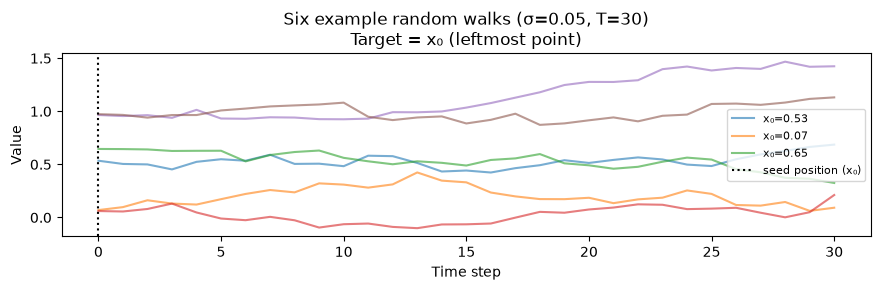

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

rng = np.random.default_rng(3151)

T_SEQ   = 30    # full sequence length seen by the RNN
W_MLP   = 5     # short window seen by the MLP
SIGMA   = 0.05  # per-step noise std
N_TRAIN = 4000
N_VAL   = 1000

def make_walks(n, T, sigma, rng):
    """Generate n random walks of length T+1 starting from U(0,1)."""
    x0    = rng.uniform(0, 1, size=(n, 1))          # seed: (n, 1)
    noise = rng.normal(0, sigma, size=(n, T))        # increments: (n, T)
    steps = np.cumsum(noise, axis=1)                 # cumulative drift
    walks = np.concatenate([x0, x0 + steps], axis=1)  # (n, T+1)
    return walks.astype(np.float32)

walks_train = make_walks(N_TRAIN, T_SEQ, SIGMA, rng)
walks_val   = make_walks(N_VAL,   T_SEQ, SIGMA, rng)

# Target: x_0 (the seed, first column)
y_train = walks_train[:, 0:1]   # (N_TRAIN, 1)
y_val   = walks_val[:,   0:1]

# RNN input: full walk x_0 … x_{T-1} (T steps)  — shape (N, T, 1)
X_rnn_train = walks_train[:, :T_SEQ, np.newaxis]
X_rnn_val   = walks_val[:,   :T_SEQ, np.newaxis]

# MLP input: last W_MLP steps only  — shape (N, W_MLP)
X_mlp_train = walks_train[:, -W_MLP:]
X_mlp_val   = walks_val[:,   -W_MLP:]

# Plot a few example walks
fig, ax = plt.subplots(figsize=(9, 3))
for i in range(6):
    ax.plot(walks_train[i], alpha=0.6, label=f"x₀={walks_train[i,0]:.2f}" if i < 3 else None)
ax.axvline(x=0, color="k", linestyle=":", linewidth=1.5, label="seed position (x₀)")
ax.set_xlabel("Time step")
ax.set_ylabel("Value")
ax.set_title(f"Six example random walks (σ={SIGMA}, T={T_SEQ})\nTarget = x₀ (leftmost point)")
ax.legend(fontsize=8)
plt.tight_layout()

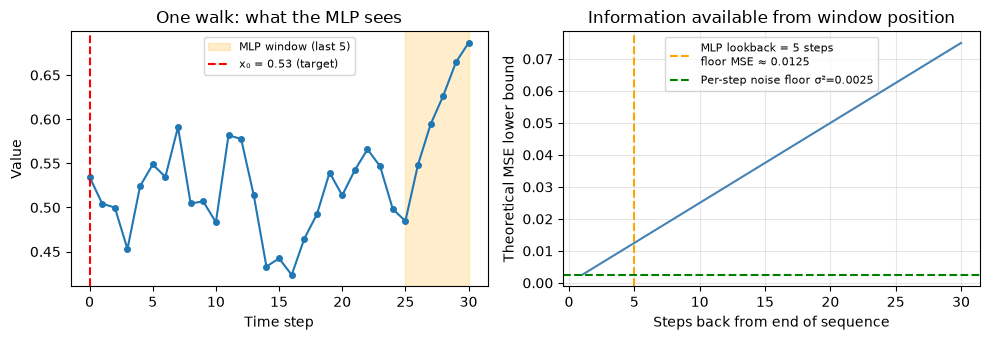

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

example = walks_train[0]
ax = axes[0]
ax.plot(np.arange(T_SEQ + 1), example, marker="o", markersize=4)
ax.axvspan(T_SEQ - W_MLP, T_SEQ, alpha=0.2, color="orange", label=f"MLP window (last {W_MLP})")
ax.axvline(0, color="red", linestyle="--", label=f"x₀ = {example[0]:.2f} (target)")
ax.set_xlabel("Time step"); ax.set_ylabel("Value")
ax.set_title("One walk: what the MLP sees"); ax.legend(fontsize=8)

# Theoretical MSE floor for MLP: variance of (x_0 - x_{T-k}) = k * sigma^2
steps_back = np.arange(1, T_SEQ + 1)
theoretical_mse = steps_back * SIGMA**2
ax2 = axes[1]
ax2.plot(steps_back, theoretical_mse, color="steelblue")
ax2.axvline(W_MLP, color="orange", linestyle="--",
            label=f"MLP lookback = {W_MLP} steps\nfloor MSE ≈ {W_MLP * SIGMA**2:.4f}")
ax2.axhline(SIGMA**2, color="green", linestyle="--",
            label=f"Per-step noise floor σ²={SIGMA**2:.4f}")
ax2.set_xlabel("Steps back from end of sequence")
ax2.set_ylabel("Theoretical MSE lower bound")
ax2.set_title("Information available from window position")
ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

plt.tight_layout()

In [33]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# --- DataLoaders ---
def rnn_loader(X, y, batch_size=128, shuffle=True):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

def mlp_loader(X, y, batch_size=128, shuffle=True):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

rnn_train_loader = rnn_loader(X_rnn_train, y_train)
rnn_val_loader   = rnn_loader(X_rnn_val,   y_val,   shuffle=False)
mlp_train_loader = mlp_loader(X_mlp_train, y_train)
mlp_val_loader   = mlp_loader(X_mlp_val,   y_val,   shuffle=False)

# --- Models ---
class VanillaRNN(nn.Module):
    """RNN sees the full walk (T=30 steps) and outputs a prediction of x_0."""
    def __init__(self, hidden_size=64):
        super().__init__()
        self.rnn  = nn.RNN(1, hidden_size, batch_first=True, nonlinearity="tanh")
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):                    # x: (B, T, 1)
        out, _ = self.rnn(x)
        return self.head(out[:, -1, :])      # use final hidden state

class MLPBaseline(nn.Module):
    """MLP sees only the last W_MLP steps; genuinely cannot see x_0."""
    def __init__(self, window=W_MLP, hidden_size=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(window, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Linear(hidden_size, 1)
        )
    def forward(self, x):                    # x: (B, W_MLP)
        return self.net(x)

rnn_model = VanillaRNN(hidden_size=64).to(device)
mlp_model = MLPBaseline(hidden_size=64).to(device)

# Naive baseline: predict the mean of training seeds (≈ 0.5)
naive_val_mse = float(np.mean((y_val - y_train.mean())**2))

print(f"RNN params : {sum(p.numel() for p in rnn_model.parameters())}")
print(f"MLP params : {sum(p.numel() for p in mlp_model.parameters())}")
print(f"Naive (predict-mean) val MSE: {naive_val_mse:.4f}  "
      f"[theoretical MLP floor ≈ {W_MLP * SIGMA**2:.4f}]")

RNN params : 4353
MLP params : 4609
Naive (predict-mean) val MSE: 0.0836  [theoretical MLP floor ≈ 0.0125]


In [34]:
def train_model(model, train_loader, val_loader, epochs=80, lr=1e-3):
    model = model.to(device)
    opt     = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"epoch": [], "train_mse": [], "val_mse": []}

    for epoch in range(1, epochs + 1):
        model.train()
        t_loss, t_n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            opt.step()
            t_loss += loss.item() * xb.size(0); t_n += xb.size(0)

        model.eval()
        v_loss, v_n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                v_loss += loss_fn(model(xb), yb).item() * xb.size(0); v_n += xb.size(0)

        history["epoch"].append(epoch)
        history["train_mse"].append(t_loss / t_n)
        history["val_mse"].append(v_loss / v_n)

    return pd.DataFrame(history)

hist_rnn = train_model(rnn_model, rnn_train_loader, rnn_val_loader, epochs=80)
hist_mlp = train_model(mlp_model, mlp_train_loader, mlp_val_loader, epochs=80)

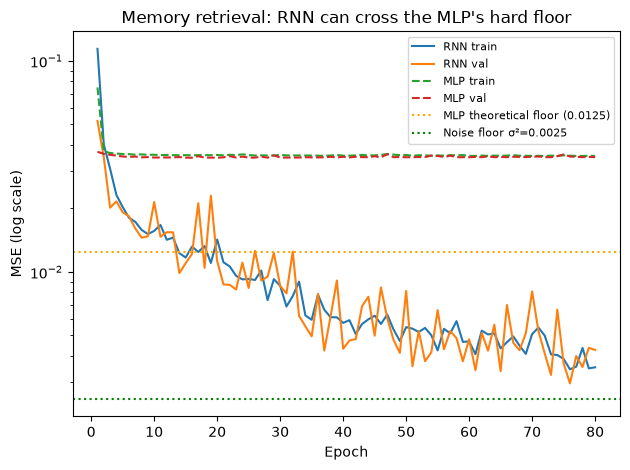

In [35]:
theoretical_floor = W_MLP * SIGMA**2

fig, ax = plt.subplots()
ax.plot(hist_rnn["epoch"], hist_rnn["train_mse"], label="RNN train")
ax.plot(hist_rnn["epoch"], hist_rnn["val_mse"],   label="RNN val")
ax.plot(hist_mlp["epoch"], hist_mlp["train_mse"], label="MLP train", linestyle="--")
ax.plot(hist_mlp["epoch"], hist_mlp["val_mse"],   label="MLP val",   linestyle="--")
ax.axhline(theoretical_floor, color="orange", linestyle=":", linewidth=1.5,
           label=f"MLP theoretical floor ({theoretical_floor:.4f})")
ax.axhline(SIGMA**2, color="green", linestyle=":", linewidth=1.5,
           label=f"Noise floor σ²={SIGMA**2:.4f}")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale)")
ax.set_yscale("log")
ax.set_title("Memory retrieval: RNN can cross the MLP's hard floor")
ax.legend(fontsize=8)
plt.tight_layout()

In [ ]:
rnn_val_mse = hist_rnn["val_mse"].iloc[-1]
mlp_val_mse = hist_mlp["val_mse"].iloc[-1]

summary = pd.DataFrame({
    "Model":              ["Vanilla RNN (T=30)", f"MLP Baseline (window={W_MLP})", "Naive (predict mean)"],
    "What it sees":       [f"Full walk: all {T_SEQ} steps", f"Last {W_MLP} steps only", "Nothing"],
    "Theoretical floor":  [f"σ²={SIGMA**2:.4f}", f"{W_MLP}σ²={W_MLP*SIGMA**2:.4f}", "Var(x₀)≈0.083"],
    "Final val MSE":      [round(rnn_val_mse, 5), round(mlp_val_mse, 5), round(naive_val_mse, 4)],
})
summary

In [21]:
from torchtext.datasets import AG_NEWS
import torch

# Older text_classification API: returns (train_dataset, test_dataset)
train_dataset, test_dataset = AG_NEWS(root="data")

# Turn into simple lists of (label, text_tensor)
full_train = list(train_dataset)
full_test  = list(test_dataset)

len(full_train), len(full_test)

120000lines [00:01, 87828.25lines/s]
120000lines [00:02, 47672.62lines/s]
7600lines [00:00, 49570.43lines/s]


(120000, 7600)

In [22]:
torch.manual_seed(3151)

train_subset_size = 20_000
val_subset_size   = 5_000
test_subset_size  = 5_000

indices   = torch.randperm(len(full_train))
train_idx = indices[:train_subset_size]
val_idx   = indices[train_subset_size:train_subset_size + val_subset_size]

train_subset = [full_train[i] for i in train_idx]
val_subset   = [full_train[i] for i in val_idx]
test_subset  = full_test[:test_subset_size]

# Sanity check one example
train_subset[0]

(2,
 tensor([  156,  1949,   937,     5, 10297,   803,   145,    14,    28,    15,
            16,     3,    52,     2,    10,     2,  1223,   156,    11,    56,
          1032,  1766,     6, 22635,   860,    18, 15706,    17,   857,     5,
           379,  2283,    43,    63,  5242,    25,     3,   101,    17,    10,
          2291, 10297,   803,     2]))

In [23]:
# AG_NEWS in this torchtext already returns token-id tensors,
# so we do NOT need to build a tokenizer/vocab manually here.

def encode(text, max_len=100):
    # Compatibility: if a tensor is passed, pad/truncate directly
    if isinstance(text, torch.Tensor):
        return pad_to_max_len(text, max_len)
    raise TypeError("Expected a tensor from AG_NEWS in this environment.")

In [24]:
def pad_to_max_len(x, max_len=100):
    # x is a 1D LongTensor of token IDs
    if x.size(0) >= max_len:
        return x[:max_len]
    pad_len = max_len - x.size(0)
    pad = torch.zeros(pad_len, dtype=torch.long)  # 0 will act as "pad"/"<unk>"
    return torch.cat([x, pad])

def prepare_dataset_tensor(examples, max_len=100):
    xs, ys = [], []
    for label, text_tensor in examples:
        xs.append(pad_to_max_len(text_tensor, max_len))
        ys.append(int(label))
    return torch.stack(xs), torch.tensor(ys)

X_train, y_train = prepare_dataset_tensor(train_subset, max_len=100)
X_val,   y_val   = prepare_dataset_tensor(val_subset,   max_len=100)
X_test,  y_test  = prepare_dataset_tensor(test_subset,  max_len=100)

X_train.shape, y_train.shape

(torch.Size([20000, 100]), torch.Size([20000]))

In [25]:
from torch.utils.data import TensorDataset, DataLoader

batch_size = 64

train_ds = TensorDataset(X_train, y_train)
val_ds   = TensorDataset(X_val,   y_val)
test_ds  = TensorDataset(X_test,  y_test)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size)
test_loader  = DataLoader(test_ds,  batch_size=batch_size)

# Infer vocab size from token-id tensors in train_subset
max_token_id = 0
for _, text_tensor in train_subset:
    if len(text_tensor) > 0:
        max_token_id = max(max_token_id, int(text_tensor.max().item()))

vocab_size = max_token_id + 1  # +1 because token IDs are 0-indexed
print("vocab_size =", vocab_size)

vocab_size = 95812


In [26]:
import torch.nn as nn

class NewsRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=128,
                 hidden_size=64, num_classes=4):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru   = nn.GRU(embed_dim, hidden_size,
                            batch_first=True, bidirectional=True)
        self.fc    = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        # x: (batch, seq_len)
        emb = self.embed(x)              # (batch, seq_len, embed_dim)
        output, h_n = self.gru(emb)      # h_n: (2, batch, hidden_size)
        h_last = torch.cat([h_n[0], h_n[1]], dim=1)  # (batch, 2 * hidden)
        logits = self.fc(h_last)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = NewsRNN(vocab_size=vocab_size).to(device)

In [27]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, train=True):
    if train:
        model.train()
    else:
        model.eval()
    total_loss, total_correct, total_examples = 0.0, 0, 0

    for X, y in loader:
        X, y = X.to(device), y.to(device)
        if train:
            optimizer.zero_grad()

        logits = model(X)
        loss   = criterion(logits, y)

        if train:
            loss.backward()
            optimizer.step()

        total_loss     += loss.item() * X.size(0)
        preds           = logits.argmax(dim=1)
        total_correct  += (preds == y).sum().item()
        total_examples += X.size(0)

    return total_loss / total_examples, total_correct / total_examples

history = {"train_loss": [], "val_loss": [],
           "train_acc": [],  "val_acc":  []}

for epoch in range(1, 9):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss,   val_acc   = run_epoch(val_loader,   train=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch}: "
          f"train_acc={train_acc:.3f}, val_acc={val_acc:.3f}, "
          f"train_loss={train_loss:.3f}, val_loss={val_loss:.3f}")

Epoch 1: train_acc=0.575, val_acc=0.783, train_loss=1.000, val_loss=0.602
Epoch 2: train_acc=0.850, val_acc=0.837, train_loss=0.431, val_loss=0.466
Epoch 3: train_acc=0.911, val_acc=0.849, train_loss=0.264, val_loss=0.437
Epoch 4: train_acc=0.947, val_acc=0.851, train_loss=0.170, val_loss=0.465


KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Accuracy
axes[0].plot(epochs, history["train_acc"], label="Train acc")
axes[0].plot(epochs, history["val_acc"],   label="Val acc", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy")
axes[0].legend()

# Loss
axes[1].plot(epochs, history["train_loss"], label="Train loss")
axes[1].plot(epochs, history["val_loss"],   label="Val loss", linestyle="--")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].set_title("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()